In [2]:
#Load modules
import pandas as pd
from sklearn.model_selection import RepeatedKFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score
from numpy import mean
from numpy import absolute
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import RandomizedSearchCV
import numpy as np


In [4]:
#pre-process the data
df = pd.read_csv("insurance.csv")

#select features
y= df['death']
X = df.drop('death',axis=1) #Select features
X = pd.get_dummies(X, drop_first=True) 

#Normalize the data
columns = X.columns #create index with column names (needed for last step)
scaler = MinMaxScaler() #initiate the scaler
X = scaler.fit_transform(X) #scale the data
X = pd.DataFrame(X,columns=columns) #turn back into a dataframe

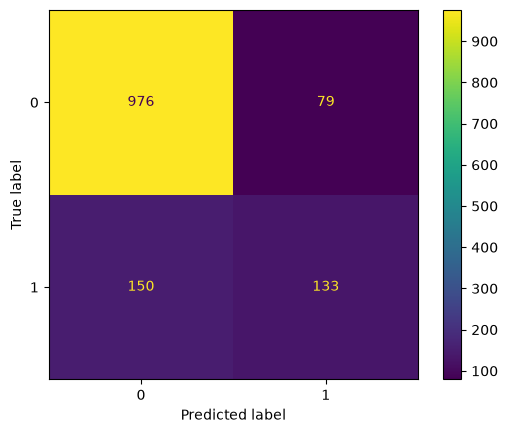

Accuracy: 0.8288490284005979


In [5]:
#Make the prediction
rf = RandomForestClassifier(n_estimators=100, random_state=69)

y_pred = cross_val_predict(rf, X, y, cv=5) #make the predictions

cm = confusion_matrix(y, y_pred) #create the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm) #create the graph
disp.plot() #plot the graph
plt.show() #show the graph

accuracy = (cm.diagonal().sum()) / cm.sum() #calculate accuracy
print("Accuracy:",accuracy) #print accuracy


In [6]:
#Calculate Gini importance
rf = RandomForestClassifier(n_estimators=100, random_state=69) #Define the model
rf.fit(X,y) #Fit the data to the random forest model
feature_importances = rf.feature_importances_ #get the GINI importances

importance_df = pd.DataFrame({ #create a dataframe shat shows the importance for each feature
    'Feature': X.columns,
    'Importance': feature_importances
})

importance_df = importance_df.sort_values(by='Importance', ascending=False) #sort the data from high to low

print(importance_df) #print the result

            Feature  Importance
1               bmi    0.391470
3           charges    0.271332
0               age    0.167591
2          children    0.061690
4          sex_male    0.030782
5        smoker_yes    0.020738
7  region_southeast    0.020283
6  region_northwest    0.019470
8  region_southwest    0.016644


In [7]:
#Hyperparameter Tuning (1)
#pre-process the data
df = pd.read_csv("insurance.csv")

#With logistic regression
y= df['charges']
X = df.drop('charges',axis=1) #Select features
X = pd.get_dummies(X, drop_first=True) 

#Normalize the data
columns = X.columns #create index with column names (needed for last step)
scaler = MinMaxScaler() #initiate the scaler
X = scaler.fit_transform(X) #scale the data
X = pd.DataFrame(X,columns=columns) #turn back into a dataframe

In [9]:
pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 39.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [optuna]2m5/6 [optuna]]]y]
Note: you may need to restart the kernel to use updated packages.


In [10]:
#Hyperparameter Tuning (2)
import optuna
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor

# Hyperparameter tuning
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 10, 250, step=10),
        'max_depth': trial.suggest_int('max_depth', 10, 250, step=10),
        'min_samples_split': trial.suggest_int('min_samples_split', 10, 30, step=1),
        'max_features': trial.suggest_categorical('max_features', [None, 'sqrt', 'log2']),
        'random_state': 69
    }
    regressor = RandomForestRegressor(**params)
    score = cross_val_score(regressor, X, y, cv=5, scoring='neg_mean_absolute_error', n_jobs=-1).mean()
    return score

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=100)  # search across 100 different combinations

print("Best params:", study.best_params)

/usr/local/python/3.14.2/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-10-02 10:55:04,937] A new study created in memory with name: no-name-ddf2eb6f-da0b-4557-9b06-d60c9cc5bf9e
[I 2026-10-02 10:55:15,653] Trial 0 finished with value: -2975.3341564093566 and parameters: {'n_estimators': 170, 'max_depth': 30, 'min_samples_split': 11, 'max_features': 'sqrt'}. Best is trial 0 with value: -2975.3341564093566.
[I 2026-10-02 10:55:16,333] Trial 1 finished with value: -2602.1596881289042 and parameters: {'n_estimators': 70, 'max_depth': 250, 'min_samples_split': 20, 'max_features': None}. Best is trial 1 with value: -2602.1596881289042.
[I 2026-10-02 10:55:16,633] Trial 2 finished with value: -3113.8178363162474 and parameters: {'n_estimators': 50, 'max_depth': 220, 'min_samples_split': 14, 'max_featu

Best params: {'n_estimators': 120, 'max_depth': 60, 'min_samples_split': 24, 'max_features': None}


In [11]:
#Run the optimized model
regressor = RandomForestRegressor(**study.best_params,
                                      random_state=69) 
RFscores = cross_val_score(regressor, X, y, cv=5,
                           scoring='neg_mean_absolute_error')
MAE = mean(absolute(RFscores))
print ('the MAE is: %.2f' % MAE)

the MAE is: 2588.57


In [13]:
pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 64.1 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 305.1/305.1 MB 43.0 MB/s  0:00:06m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [xgboost]m1/2 [xgboost]
Note: you may need to restart the kernel to use updated packages.


In [14]:
#Prediction with XGBoost
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Make the prediction
xgb = XGBClassifier(n_estimators=100, random_state=69, eval_metric='logloss')
y_pred = cross_val_predict(xgb, X, y, cv=5)  # make the predictions
cm = confusion_matrix(y, y_pred)  # create the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm)  # create the graph
disp.plot()  # plot the graph
plt.show()  # show the graph
accuracy = (cm.diagonal().sum()) / cm.sum()  # calculate accuracy
print("Accuracy:", accuracy)  # print accuracy

ValueError: Invalid classes inferred from unique values of `y`.  Expected: [   0    1    2 ... 1067 1068 1069], got [ 1121.8739   1131.5066   1135.9407  ... 60021.39897 62592.87309
 63770.42801]

In [7]:
import optuna
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'random_state': 69,
        'eval_metric': 'logloss'
    }
    model = XGBClassifier(**params)
    score = cross_val_score(model, X, y, cv=5, scoring='accuracy').mean()
    return score

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=100)

print("Best params:", study.best_params)
print("Best accuracy:", study.best_value)

c:\Users\Tijmen\anaconda3\envs\env2526\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-07-02 14:39:24,620] A new study created in memory with name: no-name-75c9fc5f-ff47-465f-8159-2882561ed799
[I 2026-07-02 14:39:25,334] Trial 0 finished with value: 0.8056962379115656 and parameters: {'n_estimators': 165, 'max_depth': 7, 'learning_rate': 0.25488423993920595, 'subsample': 0.6795633512966371, 'colsample_bytree': 0.8719245540066537, 'min_child_weight': 2}. Best is trial 0 with value: 0.8056962379115656.
[I 2026-07-02 14:39:26,639] Trial 1 finished with value: 0.8243585443568673 and parameters: {'n_estimators': 485, 'max_depth': 8, 'learning_rate': 0.04748901847254695, 'subsample': 0.5236793925010714, 'colsample_bytree': 0.5924772053323033, 'min_child_weight': 2}. Best is trial 1 with value: 0.8243585443568673

Best params: {'n_estimators': 115, 'max_depth': 9, 'learning_rate': 0.020645339850686156, 'subsample': 0.6834325710726653, 'colsample_bytree': 0.6864426176892111, 'min_child_weight': 7}
Best accuracy: 0.8490273352339427
